# YOLOv8 vs. Faster R-CNN vs. Mask R-CNN
### One-stage vs. two-stage object detection and instance segmentation, compared on speed and output

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YOUR_USER/YOUR_REPO/blob/main/yolo_vs_rcnn_comparison.ipynb)

This notebook runs pretrained detectors from two model families on the same image and compares them:

| Task | One-stage | Two-stage |
|---|---|---|
| Object detection | YOLOv8n | Faster R-CNN (ResNet-50 FPN) |
| Instance segmentation | YOLOv8n-seg | Mask R-CNN (ResNet-50 FPN) |

**Questions this notebook answers**
1. How much faster is a one-stage detector than a two-stage detector on the same hardware?
2. Do both families find the same objects at the same confidence threshold?
3. What does each architecture look like (parameters, components)?

**Stages**
0. Setup and configuration
1. Load the test image
2. Load the models
3. Helper functions (drawing, timing)
4. Object detection: YOLOv8 vs. Faster R-CNN
5. Instance segmentation: YOLOv8-seg vs. Mask R-CNN
6. Benchmark: latency, FPS, detections, model size
7. Architecture overview
8. Conclusions, limitations, next steps

## Stage 0: Setup and configuration
All tunable values live in one cell. Change them here and re-run the notebook.

In [ ]:
%pip install -q ultralytics torch torchvision opencv-python-headless matplotlib pandas pillow

In [ ]:
import os
import time
import urllib.request

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision.transforms.functional as TF
from PIL import Image
from torchvision.models.detection import (
    FasterRCNN_ResNet50_FPN_Weights,
    MaskRCNN_ResNet50_FPN_Weights,
    fasterrcnn_resnet50_fpn,
    maskrcnn_resnet50_fpn,
)
from ultralytics import YOLO

# ---------------- Configuration ----------------
IMAGE_URL = "https://ultralytics.com/images/bus.jpg"   # freely usable sample image
IMAGE_PATH = "test.jpg"                                # or set your own local path
CONF_THRESHOLD = 0.5      # same confidence threshold for all models
N_WARMUP = 3              # untimed runs (GPU kernels, caches, lazy init)
N_RUNS = 10               # timed runs per model
SEED = 42
os.makedirs("assets", exist_ok=True)   # figures saved here for the README
# -----------------------------------------------

torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
YOLO_DEVICE = 0 if DEVICE.type == "cuda" else "cpu"
print(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Device: cpu


## Stage 1: Load the test image
The notebook downloads a sample image if no local file exists. Use your own image by placing it at `IMAGE_PATH`.

Image size (W x H): (810, 1080)


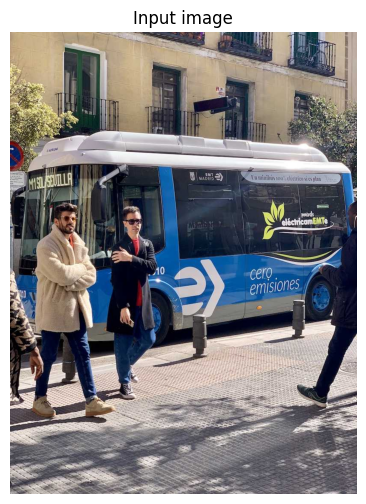

In [ ]:
if not os.path.exists(IMAGE_PATH):
    urllib.request.urlretrieve(IMAGE_URL, IMAGE_PATH)

img = Image.open(IMAGE_PATH).convert("RGB")   # RGB is required by torchvision models
print("Image size (W x H):", img.size)

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.title("Input image")
plt.show()

## Stage 2: Load the models
- **YOLOv8** (Ultralytics): one-stage detector. It predicts boxes and classes in a single pass over the image.
- **Faster R-CNN / Mask R-CNN** (torchvision): two-stage detectors. A Region Proposal Network proposes candidate regions first, then a second head classifies and refines them. Mask R-CNN adds a mask branch.

All models use COCO-pretrained weights (80 object classes), so the comparison is fair on class vocabulary.

In [ ]:
# One-stage models
yolo_det = YOLO("yolov8n.pt")
yolo_seg = YOLO("yolov8n-seg.pt")

# Two-stage models (weights=DEFAULT replaces the deprecated pretrained=True)
frcnn_weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
frcnn = fasterrcnn_resnet50_fpn(weights=frcnn_weights).to(DEVICE).eval()

mrcnn_weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
mrcnn = maskrcnn_resnet50_fpn(weights=mrcnn_weights).to(DEVICE).eval()

# torchvision returns integer labels. These tables map them to class names.
TV_CLASSES = frcnn_weights.meta["categories"]
print("Models loaded.")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 152MB/s]


Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 146MB/s]


Models loaded.


## Stage 3: Helper functions
Two things matter for a fair comparison:
- **Warm-up runs.** The first call is slow (lazy initialisation, GPU kernel loading). The original single-run timing mostly measured this overhead.
- **GPU synchronisation.** CUDA calls are asynchronous. Without `torch.cuda.synchronize()` the timer stops before the GPU finishes.

In [ ]:
def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def benchmark(fn, n_warmup=N_WARMUP, n_runs=N_RUNS):
    """Return (mean_ms, std_ms) of fn() after warm-up."""
    for _ in range(n_warmup):
        fn()
    sync()
    times = []
    for _ in range(n_runs):
        t0 = time.perf_counter()
        fn()
        sync()
        times.append((time.perf_counter() - t0) * 1000)
    return float(np.mean(times)), float(np.std(times))


def count_params_m(torch_module):
    return sum(p.numel() for p in torch_module.parameters()) / 1e6


img_tensor = TF.to_tensor(img).to(DEVICE)   # shared input for the torchvision models


def run_yolo_det():
    return yolo_det(img, conf=CONF_THRESHOLD, device=YOLO_DEVICE, verbose=False)[0]


def run_yolo_seg():
    return yolo_seg(img, conf=CONF_THRESHOLD, device=YOLO_DEVICE, verbose=False)[0]


@torch.no_grad()
def run_frcnn():
    return frcnn([img_tensor])[0]


@torch.no_grad()
def run_mrcnn():
    return mrcnn([img_tensor])[0]


def draw_tv_boxes(image, out, thr=CONF_THRESHOLD, color=(255, 0, 0)):
    """Draw torchvision detections (boxes + class name + score) on a copy of the image."""
    canvas = np.array(image).copy()
    n = 0
    for box, score, label in zip(out["boxes"], out["scores"], out["labels"]):
        if score < thr:
            continue
        n += 1
        x1, y1, x2, y2 = box.detach().cpu().numpy().astype(int).tolist()
        cv2.rectangle(canvas, (x1, y1), (x2, y2), color, 2)
        cv2.putText(canvas, f"{TV_CLASSES[label.item()]} {score:.2f}", (x1, max(12, y1 - 6)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    return canvas, n


def draw_tv_masks(image, out, thr=CONF_THRESHOLD, alpha=0.45):
    """Blend one random colour per instance mask, then draw boxes and labels."""
    rng = np.random.default_rng(SEED)
    canvas = np.array(image).copy().astype(np.float32)
    n = 0
    for mask, score in zip(out["masks"], out["scores"]):
        if score < thr:
            continue
        n += 1
        m = (mask[0] > 0.5).cpu().numpy()
        color = rng.integers(0, 255, 3)
        canvas[m] = (1 - alpha) * canvas[m] + alpha * color
    canvas = canvas.astype(np.uint8)
    canvas, _ = draw_tv_boxes(Image.fromarray(canvas), out, thr)
    return canvas, n


def yolo_to_rgb(result):
    return result.plot()[..., ::-1]   # Ultralytics returns BGR

## Stage 4: Object detection, YOLOv8 vs. Faster R-CNN
Both models run on the same image with the same confidence threshold.

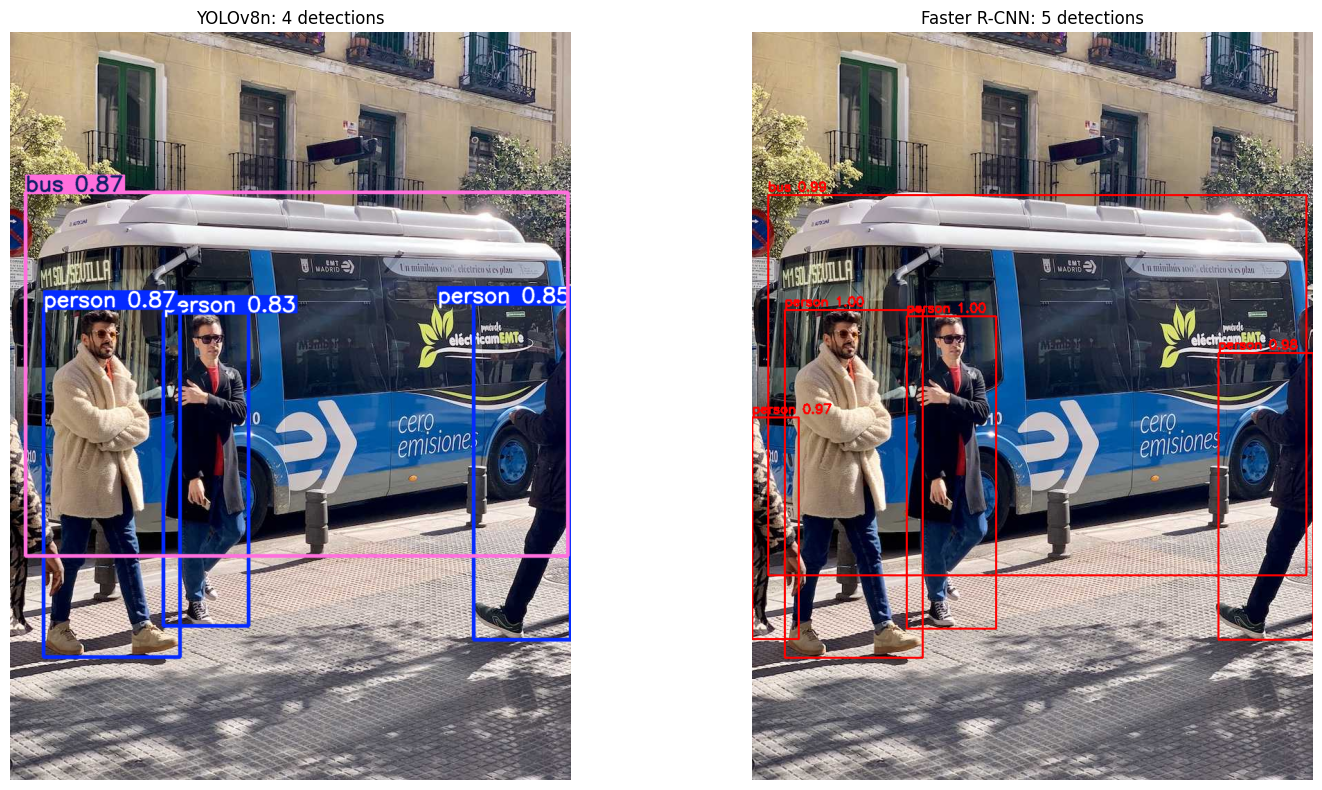

In [ ]:
res_yolo = run_yolo_det()
out_frcnn = run_frcnn()
img_frcnn, n_frcnn = draw_tv_boxes(img, out_frcnn)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(yolo_to_rgb(res_yolo))
axes[0].set_title(f"YOLOv8n: {len(res_yolo.boxes)} detections")
axes[1].imshow(img_frcnn)
axes[1].set_title(f"Faster R-CNN: {n_frcnn} detections")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("assets/detection_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**How to read this:** compare which objects each model finds, which it misses, and how the boxes fit. Small or partly hidden objects are where the two families usually differ most.

## Stage 5: Instance segmentation, YOLOv8-seg vs. Mask R-CNN
Segmentation adds a pixel mask per object on top of the box.

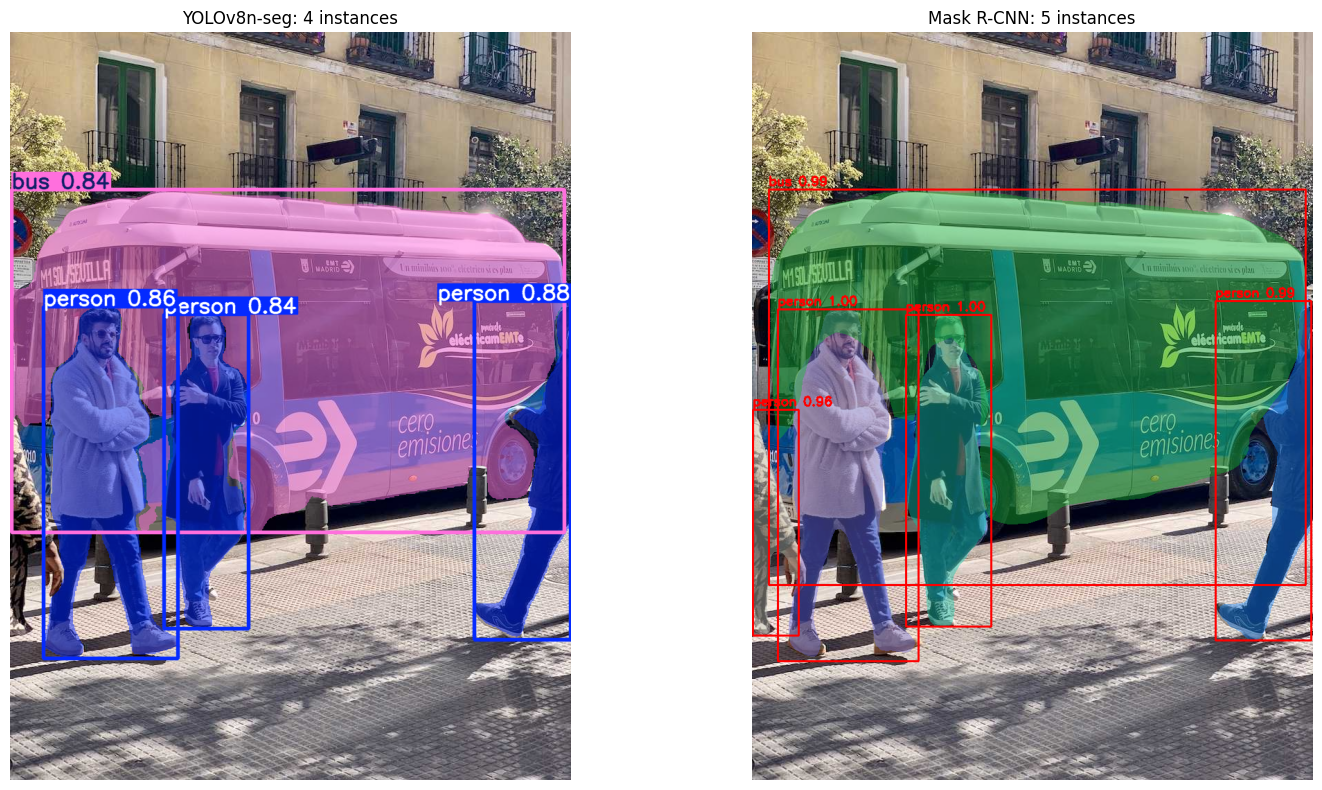

In [ ]:
res_yseg = run_yolo_seg()
out_mrcnn = run_mrcnn()
img_mrcnn, n_mrcnn = draw_tv_masks(img, out_mrcnn)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(yolo_to_rgb(res_yseg))
axes[0].set_title(f"YOLOv8n-seg: {len(res_yseg.boxes)} instances")
axes[1].imshow(img_mrcnn)
axes[1].set_title(f"Mask R-CNN: {n_mrcnn} instances")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("assets/segmentation_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## Stage 6: Benchmark
Each model runs `N_WARMUP` untimed and `N_RUNS` timed passes on the same image. Latency covers the model call, including preprocessing and NMS for YOLO and the full forward pass for torchvision.

In [ ]:
rows = []
specs = [
    ("YOLOv8n",       "detection",    run_yolo_det, lambda: len(run_yolo_det().boxes), count_params_m(yolo_det.model)),
    ("Faster R-CNN",  "detection",    run_frcnn,    lambda: int((run_frcnn()["scores"] >= CONF_THRESHOLD).sum()), count_params_m(frcnn)),
    ("YOLOv8n-seg",   "segmentation", run_yolo_seg, lambda: len(run_yolo_seg().boxes), count_params_m(yolo_seg.model)),
    ("Mask R-CNN",    "segmentation", run_mrcnn,    lambda: int((run_mrcnn()["scores"] >= CONF_THRESHOLD).sum()), count_params_m(mrcnn)),
]

for name, task, run_fn, count_fn, params in specs:
    mean_ms, std_ms = benchmark(run_fn)
    rows.append({
        "model": name,
        "task": task,
        "latency_ms": round(mean_ms, 1),
        "std_ms": round(std_ms, 1),
        "fps": round(1000 / mean_ms, 1),
        f"detections@{CONF_THRESHOLD}": count_fn(),
        "params_M": round(params, 1),
    })

df = pd.DataFrame(rows)
df.to_csv("assets/benchmark_results.csv", index=False)
df

,model,task,latency_ms,std_ms,fps,detections@0.5,params_M
0,YOLOv8n,detection,162.8,7.0,6.1,4,3.2
1,Faster R-CNN,detection,8279.5,601.1,0.1,5,41.8
2,YOLOv8n-seg,segmentation,311.9,53.4,3.2,4,3.4
3,Mask R-CNN,segmentation,8855.8,499.2,0.1,5,44.4


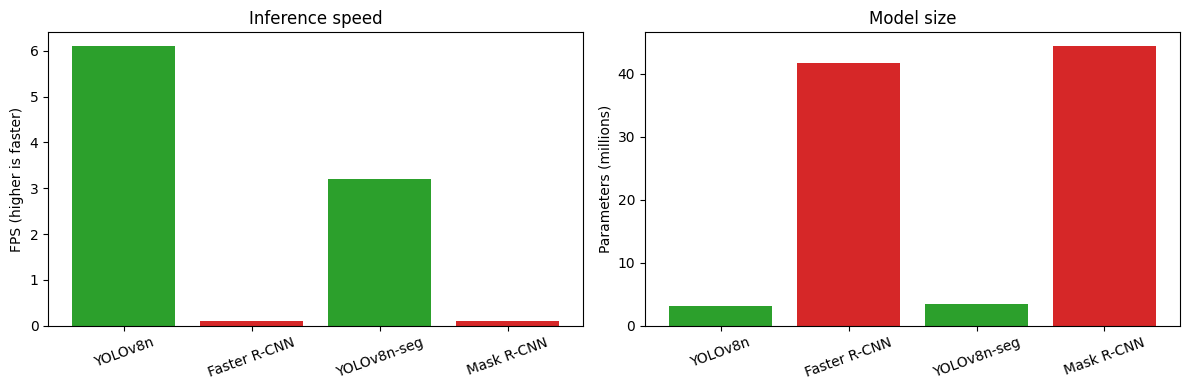

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = ["tab:green" if m.startswith("YOLO") else "tab:red" for m in df["model"]]

axes[0].bar(df["model"], df["fps"], color=colors)
axes[0].set_ylabel("FPS (higher is faster)")
axes[0].set_title("Inference speed")

axes[1].bar(df["model"], df["params_M"], color=colors)
axes[1].set_ylabel("Parameters (millions)")
axes[1].set_title("Model size")

for ax in axes:
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig("assets/benchmark.png", dpi=150, bbox_inches="tight")
plt.show()

## Stage 7: Architecture overview
Printing a full torchvision model produces hundreds of lines. This cell prints the top-level components instead.

In [ ]:
print("Faster R-CNN top-level components:")
for name, child in frcnn.named_children():
    print(f"  {name:<10} {type(child).__name__:<28} {count_params_m(child):6.2f} M params")

print("\nMask R-CNN top-level components:")
for name, child in mrcnn.named_children():
    print(f"  {name:<10} {type(child).__name__:<28} {count_params_m(child):6.2f} M params")

Faster R-CNN top-level components:
  transform  GeneralizedRCNNTransform       0.00 M params
  backbone   BackboneWithFPN               26.80 M params
  rpn        RegionProposalNetwork          0.59 M params
  roi_heads  RoIHeads                      14.36 M params

Mask R-CNN top-level components:
  transform  GeneralizedRCNNTransform       0.00 M params
  backbone   BackboneWithFPN               26.80 M params
  rpn        RegionProposalNetwork          0.59 M params
  roi_heads  RoIHeads                      17.01 M params


**Reading the output**
- `backbone`: ResNet-50 with a Feature Pyramid Network. It extracts multi-scale features.
- `rpn`: Region Proposal Network. This is the "first stage" that YOLO does not have.
- `roi_heads`: the "second stage". It classifies each proposal and refines its box. In Mask R-CNN it also predicts the masks.
- YOLOv8 folds backbone, neck and head into one network and predicts boxes directly on the feature maps.

## Stage 8: Conclusions, limitations, next steps

**Conclusions.** Read these off the table in Stage 6 after running on your hardware:
- Compare `fps` between one-stage and two-stage models to quantify the speed gap.
- Compare `params_M` to see the memory cost.
- Compare the detection counts at the shared threshold, then check visually in Stages 4 and 5 which model is right.

**Limitations**
- The comparison uses **one image**. Counts and latency on a single image do not generalise.
- The detection count is **not accuracy**. A model can return more boxes and still be wrong. Without ground-truth labels this notebook cannot compute mAP.
- YOLOv8**n** is the smallest YOLOv8 variant. Larger variants (s, m, l, x) trade speed for accuracy and would change the comparison.
- Latency includes each library's own pre- and post-processing, which differs between Ultralytics and torchvision.
- Results depend on the hardware shown in Stage 0.

**Next steps**
1. Evaluate on a labelled set (for example a COCO val2017 subset) and report **mAP@0.5:0.95** with `torchmetrics` or `pycocotools`.
2. Benchmark on a folder of images and report mean latency with a confidence interval.
3. Add YOLOv8s/m and `fasterrcnn_mobilenet_v3_large_fpn` to compare models of similar size.
4. Fine-tune both families on one custom dataset (for example an industrial inspection set) and compare.
5. Export YOLO to ONNX/TensorRT and measure the deployment speed-up.

**1. Models comparisen**

Object Detection:
- YOLOv8n: 3.2 M параметров, 6.1 FPS.
- Faster R-CNN: 41.8 M параметров, 0.1 FPS.


Instance Segmentation:
- YOLOv8n-seg: 3.4 M параметров, 3.2 FPS.
- Mask R-CNN: 44.4 M параметров, 0.1 FPS.

**2. Why does this happen?**

There are several reasons:
1. Architecture. YOLO uses a one-stage approach, whereas Faster R-CNN and Mask R-CNN use a two-stage approach.
2. Computational complexity. Faster R-CNN first generates region proposals and then classifies the objects.
3. Additional operations. Mask R-CNN also generates object masks, which requires additional computational resources.
4. Optimization. YOLO is optimized for fast inference.

**Conclusion**

The experimental results demonstrate that a higher number of trainable parameters does not necessarily lead to better performance. Although Faster R-CNN and Mask R-CNN contain approximately 13 times more parameters than their YOLO counterparts, they exhibit substantially higher inference latency and lower processing throughput. This indicates that model architecture and computational efficiency play a more important role than parameter count alone in real-time computer vision applications.